In [1]:
# Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.
# Determine the number of clusters using the elbow method.

In [3]:
import pandas as pd

df = pd.read_csv("sales_data_sample.csv", encoding = 'latin1')

In [6]:
print(df.head())
print(df.columns)
print(df.isnull().sum())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [8]:
num_cols = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']].columns

In [109]:
x = df[num_cols]
x

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
0,10107,30,95.70,2,2871.00,1,2,2003,95
1,10121,34,81.35,5,2765.90,2,5,2003,95
2,10134,41,94.74,2,3884.34,3,7,2003,95
3,10145,45,83.26,6,3746.70,3,8,2003,95
4,10159,49,100.00,14,5205.27,4,10,2003,95
...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,4,12,2004,54
2819,10373,29,100.00,1,3978.51,1,1,2005,54
2820,10386,43,100.00,4,5417.57,1,3,2005,54
2821,10397,34,62.24,1,2116.16,1,3,2005,54


In [11]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

In [12]:
x = sc.fit_transform(x)

In [15]:
from sklearn.cluster import KMeans

emc = []

In [16]:
for i in range (1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(x)
    emc.append(km.inertia_)


In [17]:
import matplotlib.pyplot as plt

([<matplotlib.axis.XTick at 0x11d9ea710>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10')])

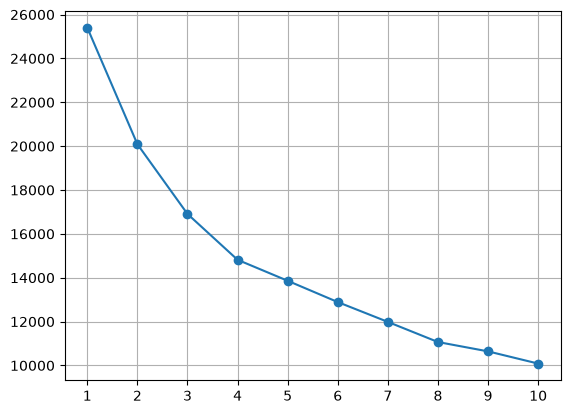

In [108]:
plt.plot(range(1,11), emc, marker = 'o')
plt.grid(True)
plt.xticks(range(1,11))

In [20]:
# Hence k = 4 elbow

In [94]:
k = 3
km = KMeans(n_clusters=k, random_state=42, n_init=10)
pred = km.fit_predict(x)

In [95]:
df["kmeans"] = pred

In [96]:
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,kmeans,Hier_cluster,cluster
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,NY,10022,USA,NaN,Yu,Kwai,Small,1,1,1
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,NaN,51100,France,EMEA,Henriot,Paul,Small,2,1,1
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium,1,1,0
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,CA,90003,USA,NaN,Young,Julie,Medium,1,1,3
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,CA,NaN,USA,NaN,Brown,Julie,Medium,1,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,12/2/2004 0:00,Shipped,4,12,2004,...,NaN,28034,Spain,EMEA,Freyre,Diego,Small,2,1,0
2819,10373,29,100.00,1,3978.51,1/31/2005 0:00,Shipped,1,1,2005,...,NaN,90110,Finland,EMEA,Koskitalo,Pirkko,Medium,0,1,2
2820,10386,43,100.00,4,5417.57,3/1/2005 0:00,Resolved,1,3,2005,...,NaN,28034,Spain,EMEA,Freyre,Diego,Medium,0,1,2
2821,10397,34,62.24,1,2116.16,3/28/2005 0:00,Shipped,1,3,2005,...,NaN,31000,France,EMEA,Roulet,Annette,Small,0,1,2


In [97]:
!pip install scipy

Defaulting to user installation because normal site-packages is not writeable


In [98]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [99]:
linked = linkage(x, method='ward')

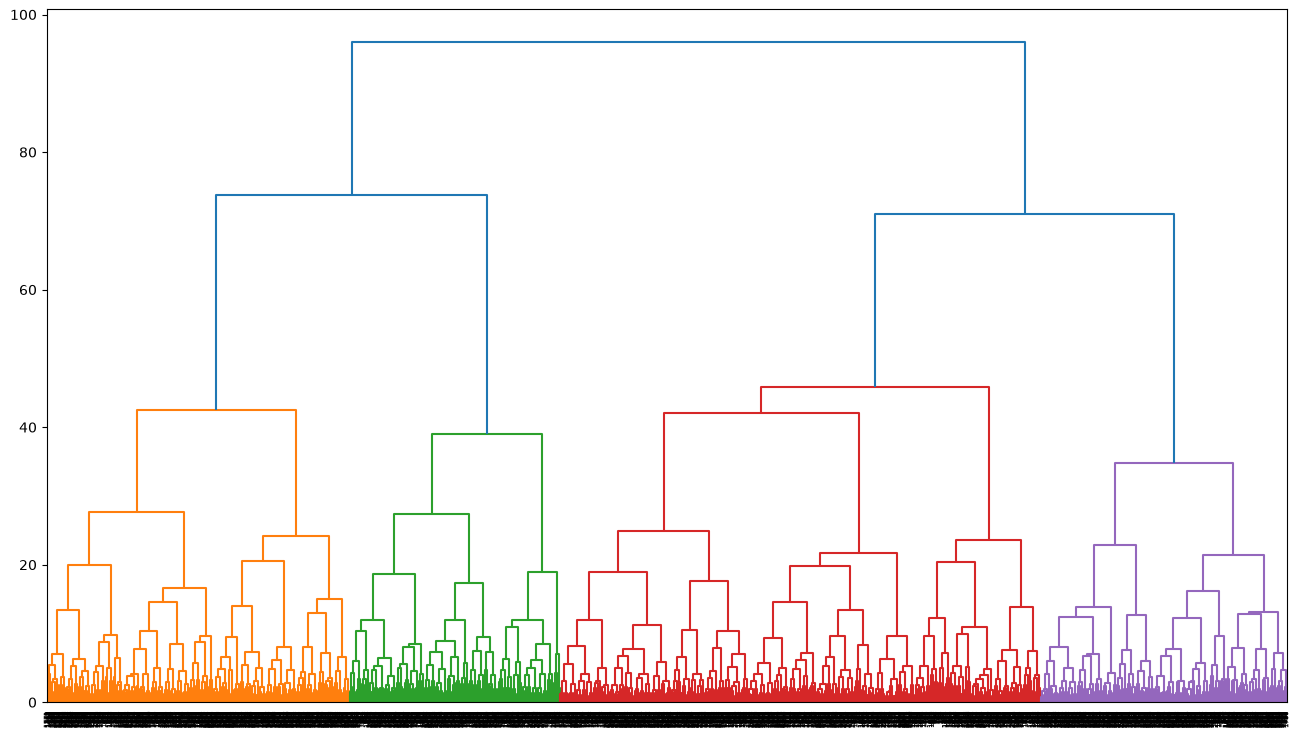

In [100]:
plt.figure(figsize=(16,9))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True)
plt.show()

In [101]:
df['Hier_cluster'] = fcluster(linked, k, criterion='maxclust')

In [102]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,kmeans,Hier_cluster,cluster
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,NY,10022,USA,NaN,Yu,Kwai,Small,1,3,1
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,NaN,51100,France,EMEA,Henriot,Paul,Small,2,3,1
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium,1,1,0
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,CA,90003,USA,NaN,Young,Julie,Medium,1,1,3
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,CA,NaN,USA,NaN,Brown,Julie,Medium,1,1,3


In [103]:
df['Hier_cluster'] = fcluster(linked, k)
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,kmeans,Hier_cluster,cluster
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,NY,10022,USA,NaN,Yu,Kwai,Small,1,1,1
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,NaN,51100,France,EMEA,Henriot,Paul,Small,2,1,1
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium,1,1,0
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,CA,90003,USA,NaN,Young,Julie,Medium,1,1,3
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,CA,NaN,USA,NaN,Brown,Julie,Medium,1,1,3


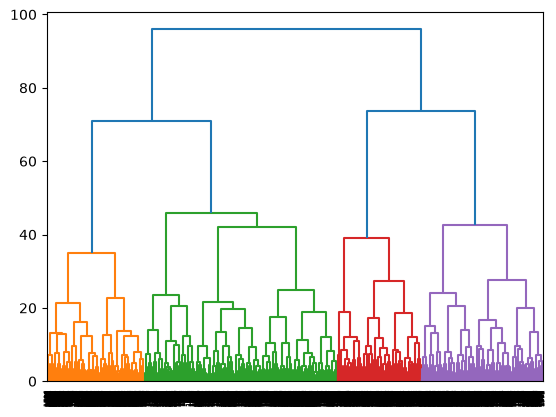

In [104]:
dendrogram(linked, p = 30)
plt.show()

In [105]:
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

label = hierarchical.fit_predict(x)

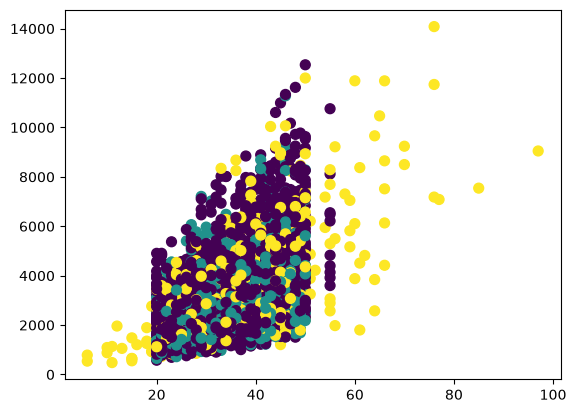

In [106]:
df['cluster'] = label

plt.scatter(df['QUANTITYORDERED'],
            df['SALES'],
               c = df['cluster'],
                cmap= 'viridis',
               
    s=50)